## Part B

### Prepare

In [ ]:
#import lib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#load the dataset
iris = load_iris(as_frame=True)

data = iris.data
y = iris.target

#standardize
scaler = StandardScaler()
X = scaler.fit_transform(data)

print("Original data shape:", data.shape)
print("Standardized data shape:", X.shape)

print("Feature means:")
print(X.mean(axis=0))

print("Feature standard deviations:")
print(X.std(axis=0))

Original data shape: (150, 4)
Standardized data shape: (150, 4)
Feature means:
[-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]
Feature standard deviations:
[1. 1. 1. 1.]


### Implement

In [2]:
# Apply PCA to the standardized dataset
pca = PCA(n_components=4)

X_pca = pca.fit_transform(X)

print("Explained variance:")
print(pca.explained_variance_)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance:
[2.93808505 0.9201649  0.14774182 0.02085386]

Explained variance ratio:
[0.72962445 0.22850762 0.03668922 0.00517871]


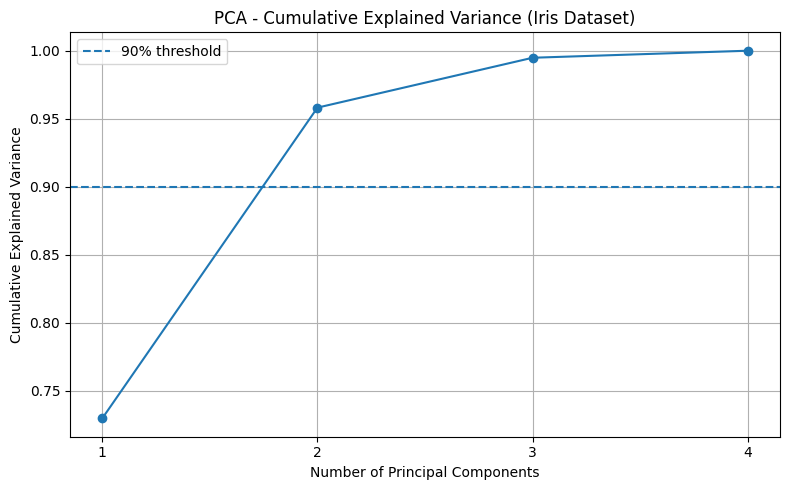

In [3]:
explained_variance_ratio = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% threshold"
)

plt.xticks(range(1, 5))
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance (Iris Dataset)")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# Extract the first two principal components
Z = X_pca[:, :2]

print("Reduced data shape:", Z.shape)

Reduced data shape: (150, 2)


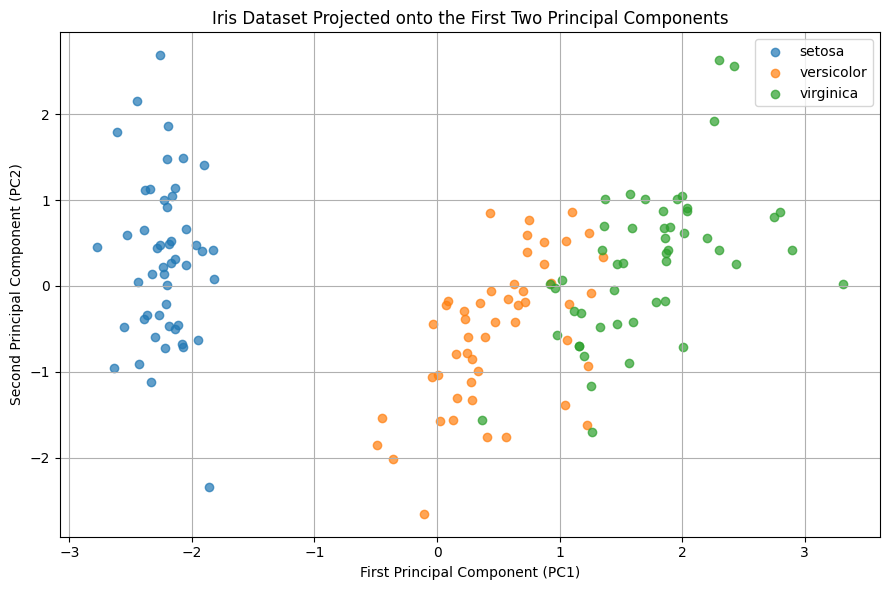

In [5]:
plt.figure(figsize=(9, 6))

species_names = iris.target_names

for i, species in enumerate(species_names):
    plt.scatter(
        Z[y == i, 0],
        Z[y == i, 1],
        label=species,
        alpha=0.7
    )

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("Iris Dataset Projected onto the First Two Principal Components")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Center the standardized data
X_mean = X.mean(axis=0)
X_centered = X - X_mean

print("Centered data shape:", X_centered.shape)
print("Mean after centering:", X_centered.mean(axis=0))

Centered data shape: (150, 4)
Mean after centering: [ 2.37957802e-16  1.89848137e-16 -5.75095527e-16  5.27726011e-16]


In [7]:
# Perform SVD
U, singular_values, Vt = np.linalg.svd(
    X_centered,
    full_matrices=False
)

print("Singular values:")
print(singular_values)

Singular values:
[20.92306556 11.7091661   4.69185798  1.76273239]


In [8]:
N = X_centered.shape[0]

# Eigenvalues of population covariance matrix
S = (X_centered.T @ X_centered) / N

eigenvalues, eigenvectors = np.linalg.eigh(S)

# Sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]

# Calculate eigenvalues using SVD
eigenvalues_svd = singular_values ** 2 / N

print("Eigenvalues from covariance matrix:")
print(eigenvalues)

print("\nEigenvalues from SVD:")
print(eigenvalues_svd)

print("\nDifference:")
print(eigenvalues - eigenvalues_svd)

print("\nVerification:")
print(np.allclose(eigenvalues, eigenvalues_svd))

Eigenvalues from covariance matrix:
[2.91849782 0.91403047 0.14675688 0.02071484]

Eigenvalues from SVD:
[2.91849782 0.91403047 0.14675688 0.02071484]

Difference:
[-8.88178420e-16 -2.66453526e-15 -8.88178420e-16  3.71230824e-16]

Verification:
True


In [9]:
# Number of components selected from B3
M = 2

# Extract the first M right singular vectors
V = Vt.T
V_M = V[:, :M]

# Project the centered data
Z = X_centered @ V_M

# Reconstruct the centered data
X_reconstructed_centered = Z @ V_M.T

# Restore the original standardized feature means
X_reconstructed = X_reconstructed_centered + X_mean

# Calculate the average squared reconstruction error
reconstruction_error = np.sum(
    (X - X_reconstructed) ** 2
) / N

print("Original data shape:", X.shape)
print("Reduced data shape:", Z.shape)
print("Reconstructed data shape:", X_reconstructed.shape)

print("\nAverage reconstruction error:")
print(reconstruction_error)

# Calculate the sum of discarded eigenvalues
discarded_variance = np.sum(eigenvalues[M:])

print("\nSum of discarded eigenvalues:")
print(discarded_variance)

print("\nDifference:")
print(abs(reconstruction_error - discarded_variance))

Original data shape: (150, 4)
Reduced data shape: (150, 2)
Reconstructed data shape: (150, 4)

Average reconstruction error:
0.16747171199993438

Sum of discarded eigenvalues:
0.16747171199993383

Difference:
5.551115123125783e-16


========== B1 ==========
Mean vector:
[0.33333333 0.33333333 0.33333333]

Centered data:
[[ 0.66666667 -0.33333333 -0.33333333]
 [-0.33333333  0.66666667 -0.33333333]
 [-0.33333333 -0.33333333  0.66666667]]

Covariance matrix:
[[ 0.22222222 -0.11111111 -0.11111111]
 [-0.11111111  0.22222222 -0.11111111]
 [-0.11111111 -0.11111111  0.22222222]]

Is covariance matrix symmetric?
True

========== B2 ==========
2x2 covariance matrix:
[[ 0.22222222 -0.11111111]
 [-0.11111111  0.22222222]]

Eigenvalues:
[0.33333333 0.11111111]

First principal component:
[-0.70710678  0.70710678]

Variance retained:
75.0 %

========== B3 ==========
Original data shape: (150, 4)
Standardized data shape: (150, 4)

Explained variance ratio:
[0.72962445 0.22850762 0.03668922 0.00517871]

Cumulative explained variance:
[0.72962445 0.95813207 0.99482129 1.        ]

Minimum components for 90% variance:
2


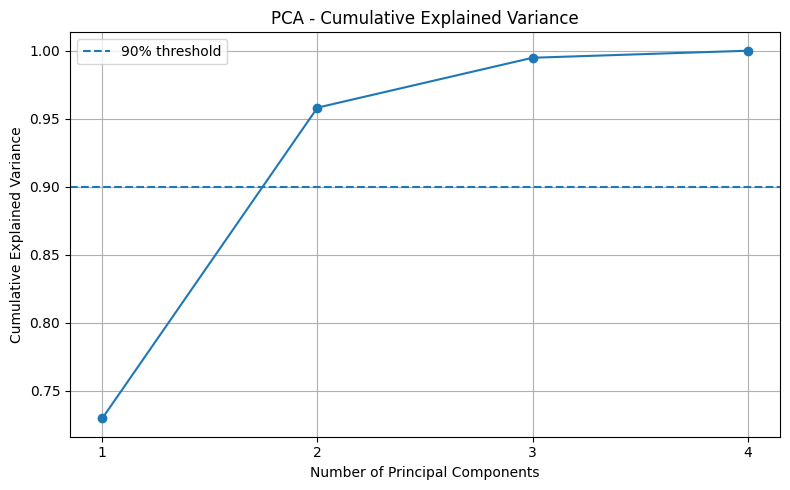


========== B4 ==========
Reduced data shape: (150, 2)


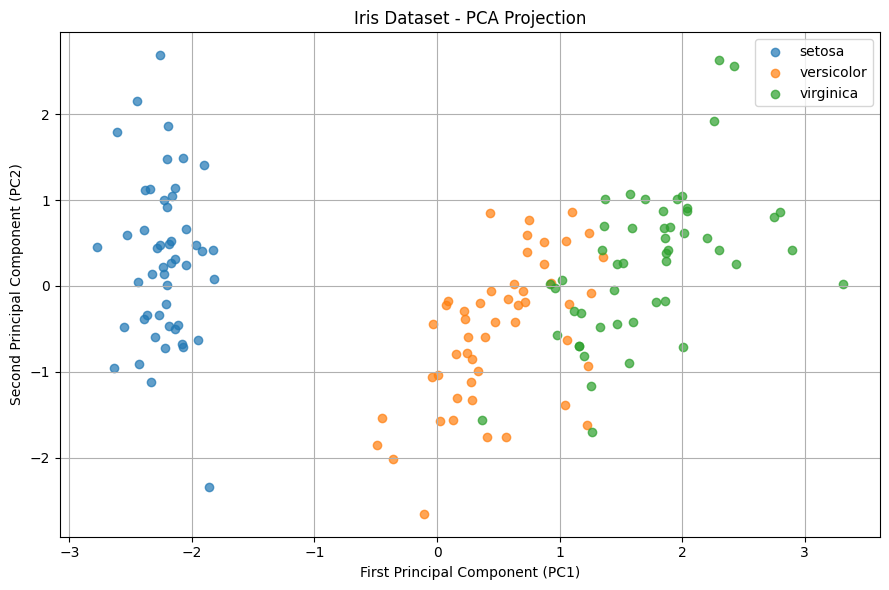


========== B5 ==========
Singular values:
[20.92306556 11.7091661   4.69185798  1.76273239]

Eigenvalues from covariance matrix:
[2.91849782 0.91403047 0.14675688 0.02071484]

Eigenvalues from SVD:
[2.91849782 0.91403047 0.14675688 0.02071484]

Verification:
True

========== B6 ==========
Number of components: 2
Original data shape: (150, 4)
Reduced data shape: (150, 2)
Reconstructed data shape: (150, 4)

Average reconstruction error:
0.16747171199993438

Sum of discarded eigenvalues:
0.16747171199993435

Absolute difference:
2.7755575615628914e-17


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# =====================================================
# B1. MANUAL COVARIANCE MATRIX
# =====================================================

# Three manually selected 3D data points
X_small = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
], dtype=float)

N_small = X_small.shape[0]

# Calculate mean vector
mean_small = X_small.mean(axis=0)

# Center the data
X_centered_small = X_small - mean_small

# Population covariance matrix (denominator N)
S_small = (
    X_centered_small.T @ X_centered_small
) / N_small

print("========== B1 ==========")
print("Mean vector:")
print(mean_small)

print("\nCentered data:")
print(X_centered_small)

print("\nCovariance matrix:")
print(S_small)

print("\nIs covariance matrix symmetric?")
print(np.allclose(S_small, S_small.T))


# =====================================================
# B2. EIGENVALUES AND FIRST PRINCIPAL COMPONENT
# =====================================================

# Extract the first 2x2 submatrix
S_2 = S_small[:2, :2]

# Calculate eigenvalues and eigenvectors
eigenvalues_2, eigenvectors_2 = np.linalg.eigh(S_2)

# Sort in descending order
idx = np.argsort(eigenvalues_2)[::-1]

eigenvalues_2 = eigenvalues_2[idx]
eigenvectors_2 = eigenvectors_2[:, idx]

# First principal component
PC1_manual = eigenvectors_2[:, 0]

# Explained variance ratio
explained_ratio_manual = (
    eigenvalues_2[0] / eigenvalues_2.sum()
)

print("\n========== B2 ==========")
print("2x2 covariance matrix:")
print(S_2)

print("\nEigenvalues:")
print(eigenvalues_2)

print("\nFirst principal component:")
print(PC1_manual)

print("\nVariance retained:")
print(explained_ratio_manual * 100, "%")


# =====================================================
# B3. PCA ON THE ENTIRE IRIS DATASET
# =====================================================

# Load Iris dataset
iris = load_iris()

data = iris.data
y = iris.target

# Standardize all four numerical features
scaler = StandardScaler()
X = scaler.fit_transform(data)

print("\n========== B3 ==========")
print("Original data shape:", data.shape)
print("Standardized data shape:", X.shape)

# Apply PCA
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X)

# Explained variance ratio
explained_variance_ratio = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(
    explained_variance_ratio
)

print("\nExplained variance ratio:")
print(explained_variance_ratio)

print("\nCumulative explained variance:")
print(cumulative_variance)

# Find the minimum components to retain 90% variance
M = np.argmax(cumulative_variance >= 0.90) + 1

print("\nMinimum components for 90% variance:")
print(M)

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% threshold"
)

plt.xticks(range(1, 5))
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# =====================================================
# B4. PROJECT DATA ONTO THE FIRST TWO COMPONENTS
# =====================================================

Z = X_pca[:, :2]

print("\n========== B4 ==========")
print("Reduced data shape:", Z.shape)

# Plot observations by species
plt.figure(figsize=(9, 6))

for i, species in enumerate(iris.target_names):
    plt.scatter(
        Z[y == i, 0],
        Z[y == i, 1],
        label=species,
        alpha=0.7
    )

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("Iris Dataset - PCA Projection")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================================
# B5. PCA USING SVD
# =====================================================

# Center standardized data
X_mean = X.mean(axis=0)
X_centered = X - X_mean

N = X_centered.shape[0]

# Population covariance matrix
S = (X_centered.T @ X_centered) / N

# Eigenvalue decomposition of covariance matrix
eigenvalues_cov, eigenvectors_cov = np.linalg.eigh(S)

# Sort descending
idx = np.argsort(eigenvalues_cov)[::-1]

eigenvalues_cov = eigenvalues_cov[idx]
eigenvectors_cov = eigenvectors_cov[:, idx]

# Singular Value Decomposition
U, singular_values, Vt = np.linalg.svd(
    X_centered,
    full_matrices=False
)

# Eigenvalues calculated from SVD
eigenvalues_svd = singular_values ** 2 / N

print("\n========== B5 ==========")

print("Singular values:")
print(singular_values)

print("\nEigenvalues from covariance matrix:")
print(eigenvalues_cov)

print("\nEigenvalues from SVD:")
print(eigenvalues_svd)

print("\nVerification:")
print(np.allclose(eigenvalues_cov, eigenvalues_svd))


# =====================================================
# B6. DATA RECONSTRUCTION AND RECONSTRUCTION ERROR
# =====================================================

# Use the number of components found in B3
V = Vt.T
V_M = V[:, :M]

# Project data onto M principal components
Z_M = X_centered @ V_M

# Reconstruct centered data
X_reconstructed_centered = Z_M @ V_M.T

# Restore the mean
X_reconstructed = X_reconstructed_centered + X_mean

# Average squared Euclidean reconstruction error
reconstruction_error = (
    np.sum((X - X_reconstructed) ** 2) / N
)

# Sum of discarded eigenvalues
discarded_variance = np.sum(
    eigenvalues_svd[M:]
)

print("\n========== B6 ==========")

print("Number of components:", M)

print("Original data shape:", X.shape)
print("Reduced data shape:", Z_M.shape)
print("Reconstructed data shape:", X_reconstructed.shape)

print("\nAverage reconstruction error:")
print(reconstruction_error)

print("\nSum of discarded eigenvalues:")
print(discarded_variance)

print("\nAbsolute difference:")
print(abs(reconstruction_error - discarded_variance))
